# Hipótesis multivariadas

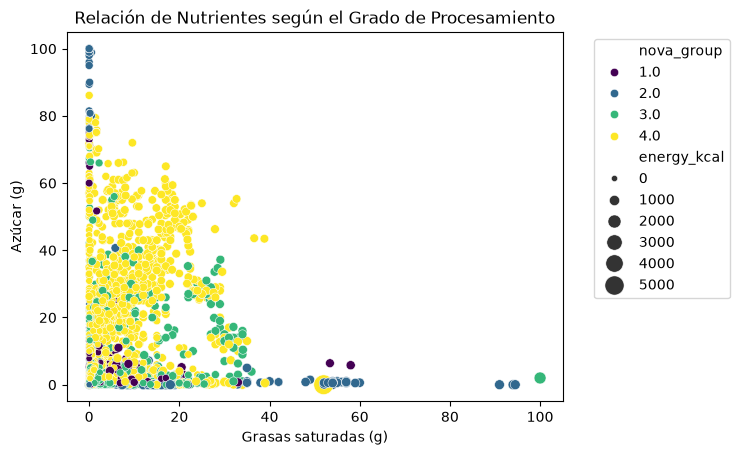

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

h3_dataset = dataset
sns.scatterplot(
    data=h3_dataset, 
    x='saturated_fat_100g', 
    y='sugars_100g', 
    hue='nova_group',  # Variable dependiente (Color)
    size='energy_kcal',    # Tercera variable independiente (Tamaño)
    sizes=(20, 200),            # Controla el tamaño mínimo y máximo de las burbujas
    palette='viridis'          
)

plt.title('Relación de Nutrientes según el Grado de Procesamiento')
plt.xlabel('Grasas saturadas (g)')
plt.ylabel('Azúcar (g)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') 
plt.show()


Se puede ver en el scatterplot que la mayoría de productos que no son ultraprocesados se concentran en la esquina inferior izquierda del gráfico, indicando que tienen cantidades bajas de azúcares y grasas saturadas. Los puntos amarillos, que representan los productos ultraprocesados, están más dispersos pero se concentran en cantidades de azúcar media-altas y en cantidades media-bajas de grasas saturadas. El tamaño del radio de los puntos, que representa las calorías, no parece destacarse de forma significativa. Para corroborar nuestra hipótesis, haremos una regresión logística, con nuestra variable dependiente siendo nova_group, y nuestras variables independientes siendo sugars_100g, saturated_fat_100g y energy_kcal. Primero evaluaremos la multicolinealidad entre las variables independientes:

--- Resultados del Test VIF ---
             Variable       VIF
0         energy_kcal  1.573758
1         sugars_100g  1.076020
2  saturated_fat_100g  1.481538


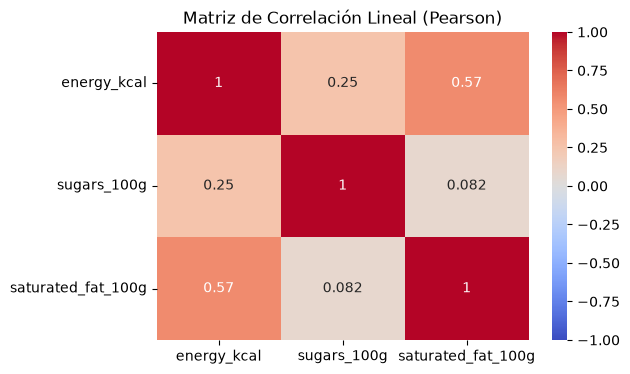

In [ ]:
import matplotlib.pyplot as plt
from statsmodels.stats.outliers_influence import variance_inflation_factor

h3_dataset = h3_dataset.dropna(subset=['energy_kcal', 'sugars_100g', 'saturated_fat_100g', 'nova_group'])  # Eliminar filas con valores nulos

# TEST DE MULTICOLINEALIDAD: VIF (Variance Inflation Factor)
X_vif = h3_dataset[['energy_kcal', 'sugars_100g', 'saturated_fat_100g']].copy()
X_vif['intercepto'] = 1  # Requerido por statsmodels

vif_data = pd.DataFrame()
vif_data["Variable"] = X_vif.columns[:-1]
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1]-1)]
print("--- Resultados del Test VIF ---")
print(vif_data)

# =========================================================
# GRÁFICO DE CORRELACIÓN (Heatmap)
# =========================================================
plt.figure(figsize=(6, 4))
sns.heatmap(h3_dataset[['energy_kcal', 'sugars_100g', 'saturated_fat_100g']].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlación Lineal (Pearson)')
plt.show()

Como todos los valores dieron menores a 5, podemos decir que no hay colinealidad entre las variables independientes. Proseguimos con el test de regresión logística:

=================== RESUMEN DEL MODELO LOGÍSTICO ===================
                             OrderedModel Results                             
Dep. Variable:             nova_group   Log-Likelihood:                -4325.2
Model:                   OrderedModel   AIC:                             8662.
Method:            Maximum Likelihood   BIC:                             8701.
Date:                Mon, 02 Nov 2026                                         
Time:                        22:51:38                                         
No. Observations:                4263                                         
Df Residuals:                    4257                                         
Df Model:                           3                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
energy_kcal         8.412e-05      0.000      

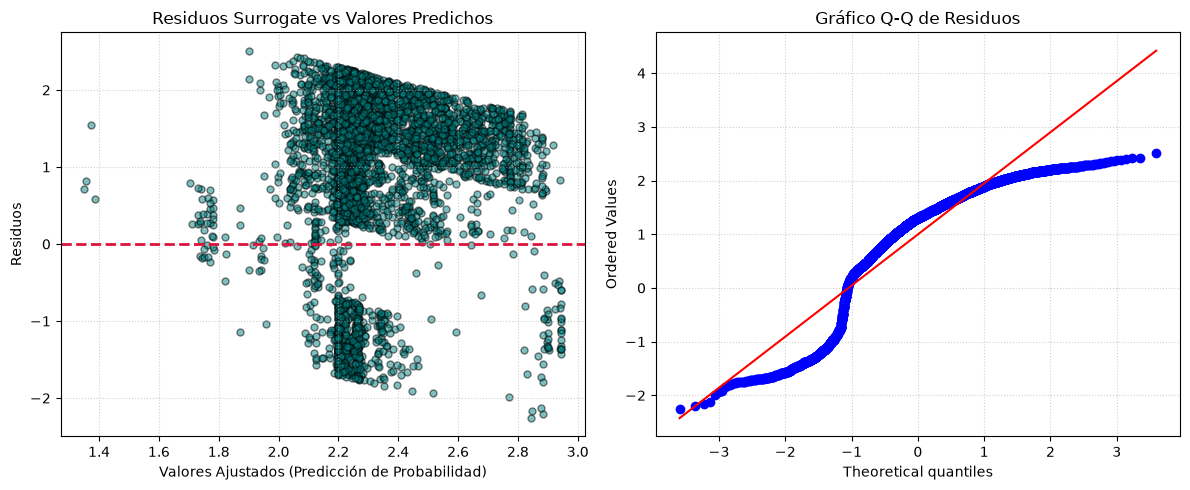

=== MATRIZ DE CONFUSIÓN ===
[[   0    0    0    0    0]
 [   0    0    0  496    0]
 [   3    0    1  175    0]
 [   1    0    0 1062    0]
 [   0    0    0 2525    0]]


In [ ]:
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.metrics import classification_report, confusion_matrix

# --- CONFIGURACIÓN DEL MODELO CON CALORÍAS INCLUIDAS ---
X_final = h3_dataset[['energy_kcal', 'sugars_100g', 'saturated_fat_100g']]
y_final = h3_dataset['nova_group'] 

# Entrenamos la Regresión Logística Ordinal
modelo_final = OrderedModel(y_final, X_final, distr='logit')
resultado_final = modelo_final.fit(method='bfgs', disp=False)
print("=================== RESUMEN DEL MODELO LOGÍSTICO ===================")
print(resultado_final.summary())

# --- ESTUDIO AVANZADO DE RESIDUALES SURROGATE ---
n_muestras = len(h3_dataset)
prob_predichas = resultado_final.predict(X_final)
valores_ajustados = np.sum(prob_predichas * np.arange(prob_predichas.shape[1]), axis=1)

# Generación del residuo simulado continuo para diagnóstico gráfico
residuos_surrogate = y_final - valores_ajustados + np.random.uniform(-0.5, 0.5, n_muestras)

# --- GRÁFICOS DE DIAGNÓSTICO ---
plt.figure(figsize=(12, 5))

# Grafico 1: Homocedasticidad (Residuos vs Ajustados)
plt.subplot(1, 2, 1)
plt.scatter(valores_ajustados, residuos_surrogate, alpha=0.5, color='teal', edgecolor='k', s=25)
plt.axhline(y=0, color='crimson', linestyle='--', linewidth=2)
plt.title('Residuos Surrogate vs Valores Predichos')
plt.xlabel('Valores Ajustados (Predicción de Probabilidad)')
plt.ylabel('Residuos')
plt.grid(True, linestyle=':', alpha=0.6)

# Grafico 2: Normalidad (Q-Q Plot)
plt.subplot(1, 2, 2)
stats.probplot(residuos_surrogate, dist="norm", plot=plt)
plt.title('Gráfico Q-Q de Residuos')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# Gráfico 3: De confusión
prob_predichas = resultado_final.predict(X_final)
y_pred = prob_predichas.idxmax(axis=1)
print("=== MATRIZ DE CONFUSIÓN ===")
print(confusion_matrix(y_final, y_pred))


Como en el scatterplot de los residuales podemos ver un patrón en vez de una nube de puntos horizontal, no se cumple el supuesto de la homocedasticidad ni de la linealidad. Además, tampoco se cumple que sean normales, ya que sino el gráfico del QQ-plot debería ser una línea recta. Al no cumplirse estos supuestos, no podemos confiar en el resultado del test de la regresión logística.